In [8]:
import os
import random
import numpy as np
import pandas as pd
import rasterio
import numpy as np
import earthpy.plot as ep
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import from_levels_and_colors
from IPython.display import Image

In [11]:
# path_tif_img = "/run/media/superuser/Almacen/mapbiomas/dadosCol10/array_tif_g2C"
path_tif_img = "/home/superuser/Dados/mapbiomas/mapping_areas_eolicas_fotovoltaicas/src/dados/array_tif_g2C"
path_tif_pred = "/home/superuser/Dados/mapbiomas/mapping_areas_eolicas_fotovoltaicas/src/dados/array_pred_tif_g2C/2024"

In [12]:
fileslist = os.listdir(path_tif_pred)
print(f" load files {len(list(fileslist))}")
print(fileslist[:2])

 load files 20
['reg_00000000000000000004_2024_7_pred.tif', 'reg_00000000000000000000_2024_10_pred.tif']


In [6]:
def hex_to_rgb(hex):
    return tuple(int(hex[i:i+2], 16) for i in (0, 2, 4))

def rgb_to_hex(r, g, b):
    return ('{:02X}' * 3).format(r, g, b)

def frame_image(img, frame_width):
    b = frame_width # border size in pixel
    ny, nx = img.shape[0], img.shape[1] # resolution / number of pixels in x and y
    if img.ndim == 3: # rgb or rgba array
        framed_img = np.zeros((b+ny+b, b+nx+b, img.shape[2]))
    elif img.ndim == 2: # grayscale image
        framed_img = np.zeros((b+ny+b, b+nx+b))
    framed_img[b:-b, b:-b] = img
    return framed_img

def convertInt16_to_Int8(myArray):
    nmin = np.min(myArray)
    nmax = np.max(myArray)
    # print("extreme before >> minimo ", nmin, "  |  maximo ", nmax)
    newArray = ((myArray - nmin) / (nmax - nmin)) * 255
    # newArray = (myArray  / 5000) * 255

    return newArray.astype(np.uint8)

def drawContour(segm, hexcolor):
    # Fill contour "c" with white, make all else black  #fc8d59 (251,141,89)
    colorRGB =  hex_to_rgb(hexcolor[1:])
    segm = np.array(segm)                                             #(rgb(22,33,43))
    ContourR = np.where(segm == 0, colorRGB[0], segm)
    ContourG = np.where(segm == 0, colorRGB[1], segm)
    ContourB = np.where(segm == 0, colorRGB[2], segm)

    imgSeg = np.stack([ContourR,ContourG,ContourB])
    # print(imgSeg.shape)
    imgSeg = np.transpose(imgSeg,[2, 1, 0])

    return imgSeg

def show_image_pred(name_array):
    path_img = os.path.join(path_tif_img, name_array.replace("_pred.tif", ".tif"))
    path_pred = os.path.join(path_tif_pred, name_array)

    ds_raster = rasterio.open(path_img)
    ds_pred = rasterio.open(path_pred)
    arrayImg = []
    bnd_blue = ds_raster.read(1)
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = ds_raster.read(2)
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = ds_raster.read(2)
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))
    

    arrayImg = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(arrayImg,[2, 1, 0])
    print("dimensions of bands array  ℛ³ : ", arrayImg.shape)
    arrayPred = np.array(ds_pred.read(1))
    print(" shape of array predict", arrayPred.shape)
    rgbLabelPred = drawContour(arrayPred, '#94484c')
    
    fig, ax = plt.subplots(figsize=[14,7], nrows=1, ncols= 2)

    # ax[0].set_title('Mosaico', fontsize = 12)
    # ax[0].imshow(imgRGB, interpolation='nearest',vmin= 0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB    
    # ax[0].xaxis.set_major_locator(ticker.NullLocator())
    # ax[0].yaxis.set_major_locator(ticker.NullLocator())
    # ax[1].set_title('Label Original', fontsize = 12)
    # ax[1].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    # ax[1].xaxis.set_major_locator(ticker.NullLocator())
    # ax[1].yaxis.set_major_locator(ticker.NullLocator())

    # Plotando a imagem original no primeiro subplot (ax[0])
    ep.plot_rgb(arrayImg, ax=ax[0], title="Imagem Original")  # ,
    
    # Plotando a previsão no segundo subplot (ax[1])
    PALETTE = ['#FFFFFF', '#94484c']
    cmap, norm = from_levels_and_colors([0,1], PALETTE, extend= 'max')
    ep.plot_bands(arrayPred, cmap=cmap, norm=norm, ax=ax[1], cbar=False, title=name_array[:-4]) #, figsize=plot_size
    # ax[1].get_legend().remove()
    # ep.plot_bands(rgbLabelPred)
    # Ajustando o layout para evitar sobreposição de títulos
    # plt.tight_layout()
    # plt.axis("off")
    plt.show()

 carregando #1 >>> reg_00000000000000000000_2024_10_pred.tif


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


dimensions of bands array  ℛ³ :  (3, 1318, 912)
 shape of array predict (1318, 912)


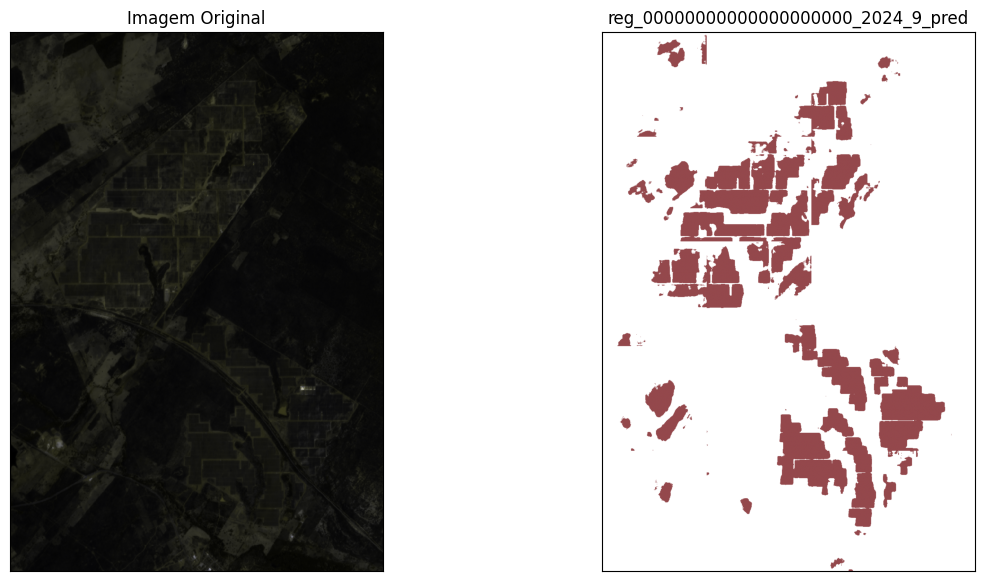

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


dimensions of bands array  ℛ³ :  (3, 1318, 912)
 shape of array predict (1318, 912)


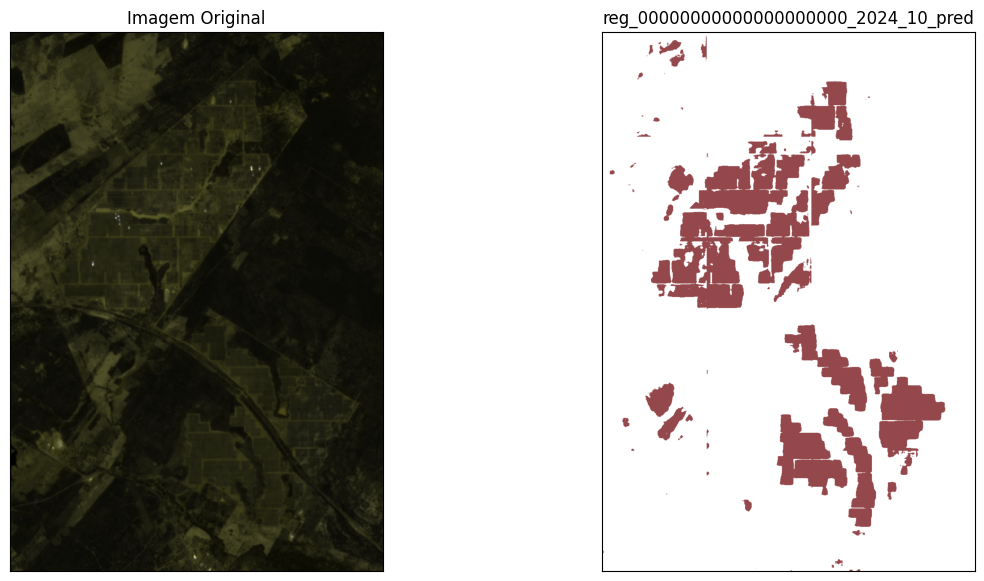

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


dimensions of bands array  ℛ³ :  (3, 1318, 912)
 shape of array predict (1318, 912)


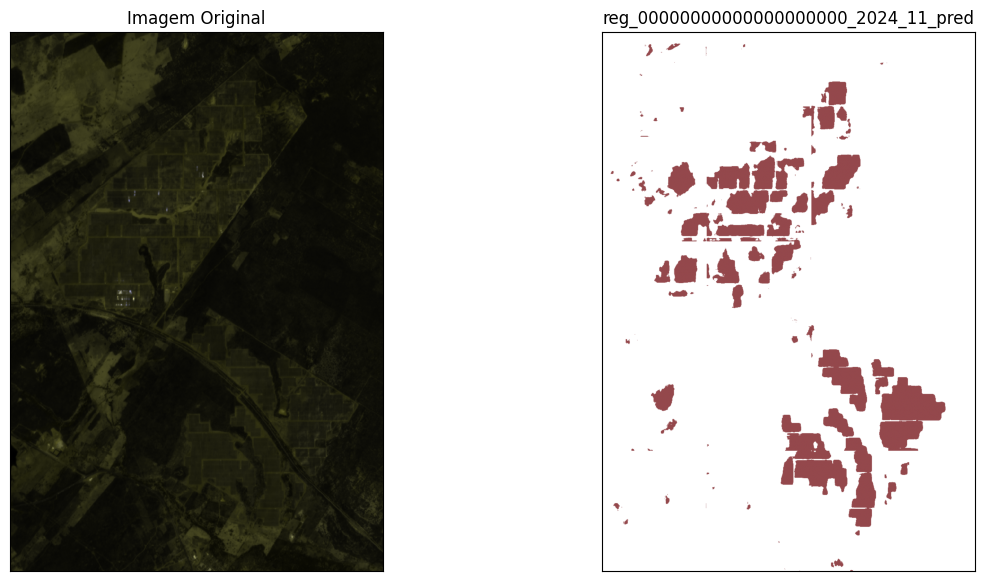

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


dimensions of bands array  ℛ³ :  (3, 361, 446)
 shape of array predict (361, 446)


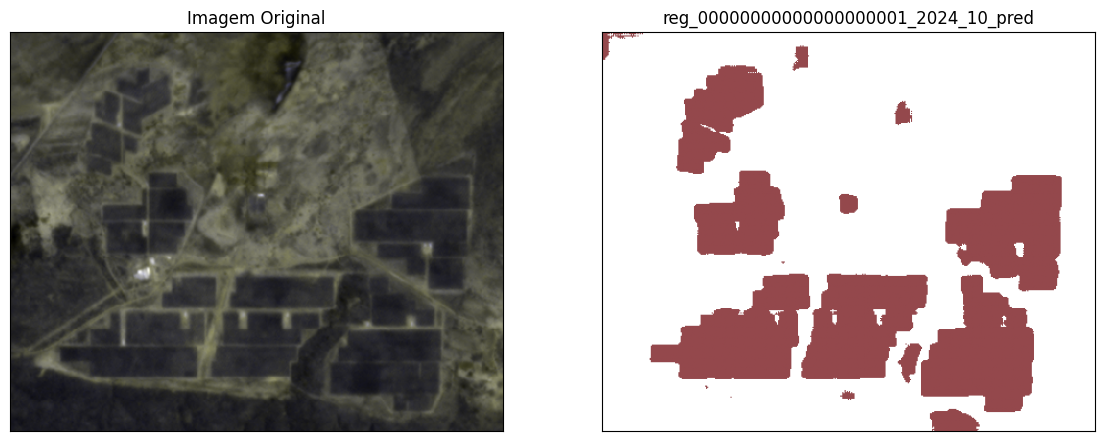

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


dimensions of bands array  ℛ³ :  (3, 403, 318)
 shape of array predict (403, 318)


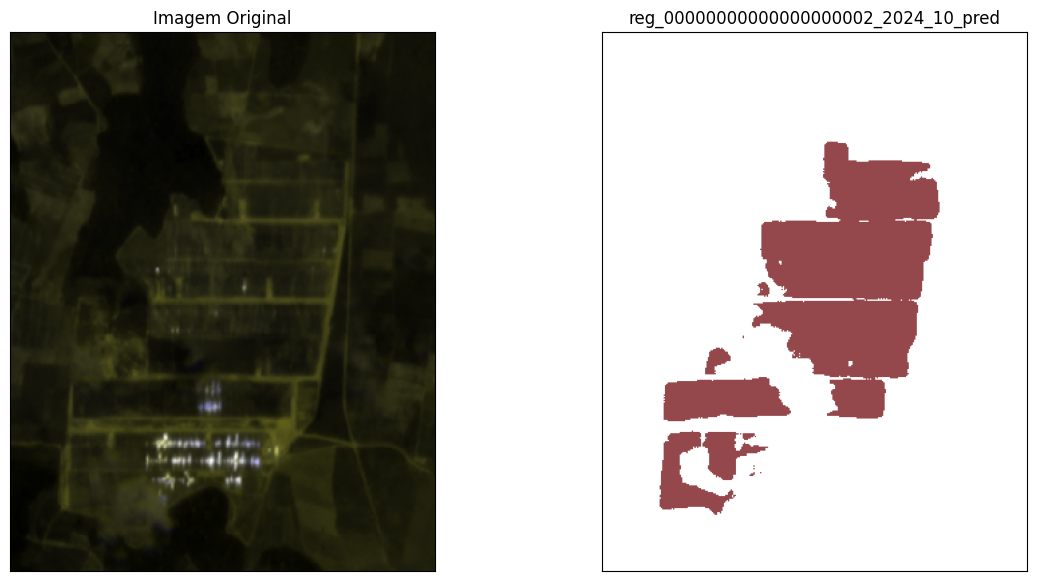

RasterioIOError: /home/superuser/Dados/mapbiomas/mapping_areas_eolicas_fotovoltaicas/src/dados/array_pred_tif_g2C/2024/reg_00000000000000000003_2024_10_pred.tif: No such file or directory

In [13]:
idShow = random.randint(0, len(fileslist) - 1)
print(f" carregando #{idShow} >>> {fileslist[idShow]}")
# name_Array = fileslist[idShow]
# show_image_pred(fileslist[idShow])
show_image_pred('reg_00000000000000000000_2024_9_pred.tif')
show_image_pred('reg_00000000000000000000_2024_10_pred.tif')
show_image_pred('reg_00000000000000000000_2024_11_pred.tif')
show_image_pred('reg_00000000000000000001_2024_10_pred.tif')
show_image_pred('reg_00000000000000000002_2024_10_pred.tif')
show_image_pred('reg_00000000000000000003_2024_10_pred.tif')
show_image_pred('reg_00000000000000000004_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000005_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000006_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000007_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000008_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000009_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000000a_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000000b_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000000c_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000014_2024_9_pred.tif')
# show_image_pred('reg_00000000000000000014_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000014_2024_11_pred.tif')
# show_image_pred('reg_0000000000000000001e_2024_9_pred.tif')
# show_image_pred('reg_0000000000000000001e_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000001e_2024_11_pred.tif')
# show_image_pred('reg_00000000000000000011_2024_9_pred.tif')
# show_image_pred('reg_00000000000000000011_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000013_2024_9_pred.tif')
# show_image_pred('reg_00000000000000000013_2024_10_pred.tif')
# show_image_pred('reg_00000000000000000013_2024_11_pred.tif')
# show_image_pred('reg_0000000000000000001f_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000001c_2024_10_pred.tif')
# show_image_pred('reg_0000000000000000001b_2024_10_pred.tif')



### we test the patchs 

In [82]:
path_npy_img = "/home/superuser/Dados/mapbiomas/mapping_areas_eolicas_fotovoltaicas/src/dados/patchs_FV_g2C"
path_npy_pred = "/home/superuser/Dados/mapbiomas/mapping_areas_eolicas_fotovoltaicas/src/dados/patchs_pred_FV3_g2V0"

In [83]:
npylist = os.listdir(path_npy_pred)
print(f" load files {len(list(npylist))}")
print(npylist[:2])


 load files 443
['reg_0000000000000000001e_2024_10_g18.npy', 'reg_00000000000000000000_2024_9_g29.npy']


In [50]:
def show_arraysNPY_pred(name_array):
    path_img = os.path.join(path_npy_img, name_array)
    path_pred = os.path.join(path_npy_pred, name_array)

    ds_raster = np.load(path_img)
    ds_pred = np.load(path_pred)
    arrayImg = []
    bnd_blue = ds_raster[:,:,0]
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = ds_raster[:,:,1]
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = ds_raster[:,:,2]
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))
    

    arrayImg = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(arrayImg,[2, 1, 0])
    print("dimensions of bands array  ℛ³ : ", arrayImg.shape)
    arrayPred = np.array(ds_pred)
    rgbLabelPred = drawContour(arrayPred, '#94484c')
    
    fig, ax = plt.subplots(figsize=[14,7], nrows=1, ncols= 2)

    # ax[0].set_title('Mosaico', fontsize = 12)
    # ax[0].imshow(imgRGB, interpolation='nearest',vmin= 0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB    
    # ax[0].xaxis.set_major_locator(ticker.NullLocator())
    # ax[0].yaxis.set_major_locator(ticker.NullLocator())
    # ax[1].set_title('Label Original', fontsize = 12)
    # ax[1].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    # ax[1].xaxis.set_major_locator(ticker.NullLocator())
    # ax[1].yaxis.set_major_locator(ticker.NullLocator())

    # Plotando a imagem original no primeiro subplot (ax[0])
    ep.plot_rgb(arrayImg, ax=ax[0], title="Imagem Original")  # ,
    
    # Plotando a previsão no segundo subplot (ax[1])
    PALETTE = ['#FFFFFF', '#94484c']
    cmap, norm = from_levels_and_colors([0,1], PALETTE, extend= 'max')
    ep.plot_bands(arrayPred, cmap=cmap, norm=norm, ax=ax[1], cbar=False) #, figsize=plot_size
    # ax[1].get_legend().remove()
    # ep.plot_bands(rgbLabelPred)
    # Ajustando o layout para evitar sobreposição de títulos
    # plt.tight_layout()
    # plt.axis("off")
    plt.show()

 carregando #52 >>> reg_00000000000000000004_2024_9_g3.npy
adding >>  reg_00000000000000000007_2024_9_g2.npy
adding >>  reg_00000000000000000007_2024_9_g0.npy
adding >>  reg_00000000000000000007_2024_9_g3.npy
adding >>  reg_00000000000000000007_2024_9_g1.npy
dimensions of bands array  ℛ³ :  (3, 256, 256)


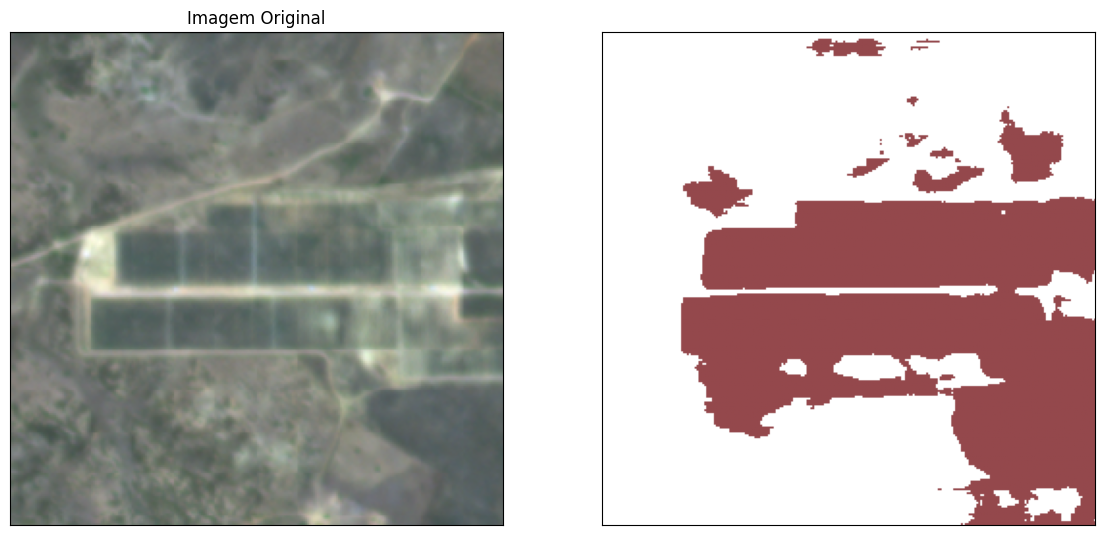

dimensions of bands array  ℛ³ :  (3, 256, 256)


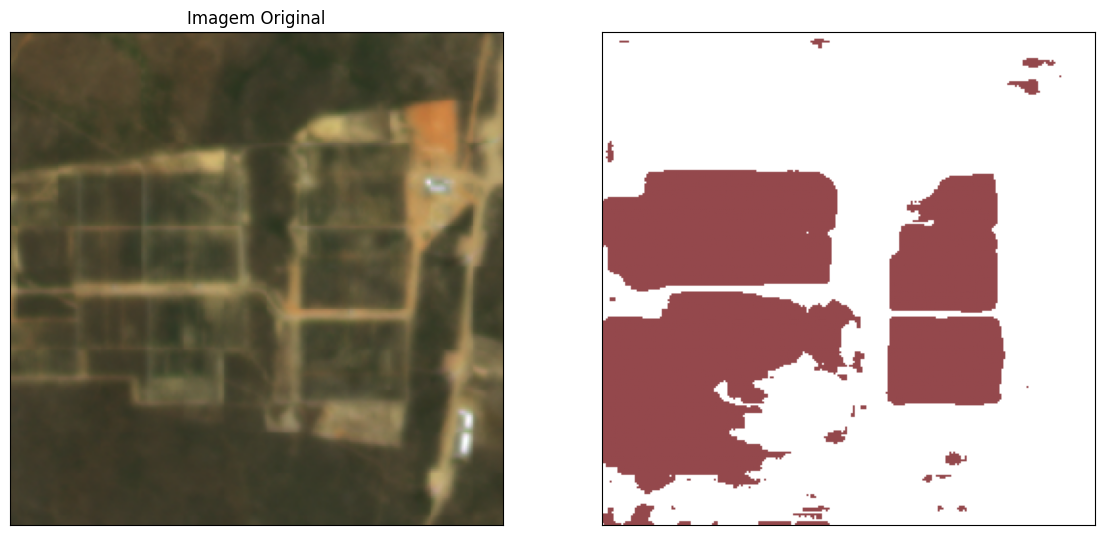

dimensions of bands array  ℛ³ :  (3, 256, 256)


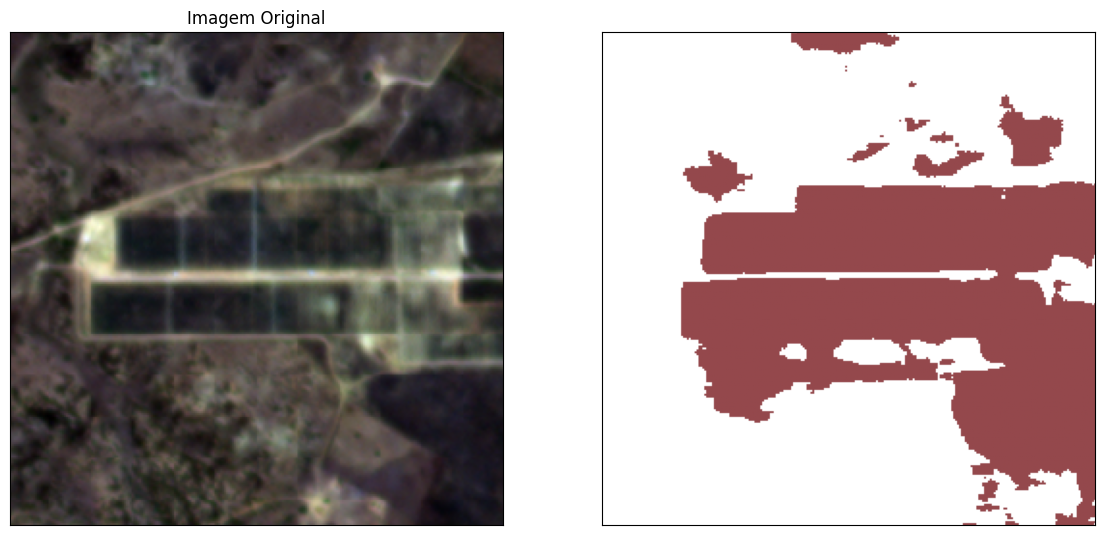

dimensions of bands array  ℛ³ :  (3, 256, 256)


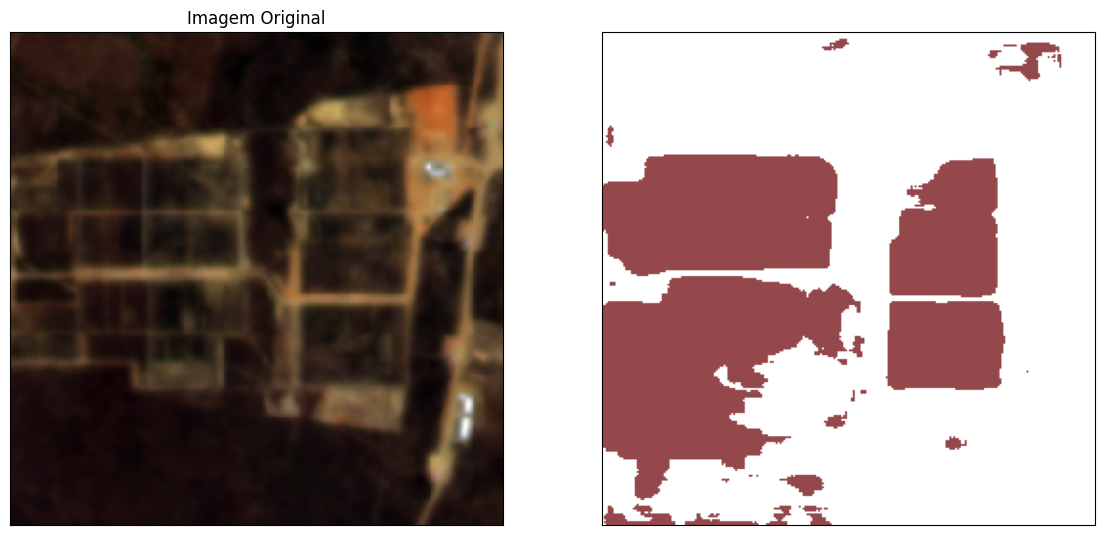

In [85]:
idShow = random.randint(0, len(npylist) - 1)
print(f" carregando #{idShow} >>> {npylist[idShow]}")
# keyId = npylist[idShow].split("_")[1]
keyId = '00000000000000000007'
month = 9
lstKeysId = []
for nameArr in npylist:
    if keyId in nameArr and str(month) in nameArr:
        lstKeysId.append(nameArr)
        print("adding >> ", nameArr)
lstKeysId.sort()     
for nameArr in lstKeysId:
    show_arraysNPY_pred(nameArr)